In [1]:
# Step 1: Import the required libraries
import pandas as pd
import matplotlib.pyplot as plt

# Load the CSV file into a DataFrame named crop_df
crop_df = pd.read_csv(r"C:\Users\dell\Downloads\crop_yield.csv")

In [2]:
# Step 2: Display the first 10 rows of the dataset
crop_df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [3]:
# Step 3: Check and count missing values in each column
crop_df.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

In [4]:
# Step 4: Display the data types of all columns
crop_df.dtypes

FARM_ID             object
CROP_TYPE           object
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE        object
DISTRICT            object
SEASON              object
FERTILIZER_USED     object
YIELD_VALUE          int64
dtype: object

In [5]:
# Step 5: Display the statistical summary of numeric columns
# This includes count, mean, standard deviation, minimum and maximum
crop_df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [6]:
# Step 6: Display the statistical summary of object columns
# This includes count, unique values, most common value and frequency
crop_df.describe(include='object')

,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


In [7]:
# Step 7: Remove rows where YIELD_KG contains missing values
crop_df = crop_df.dropna(subset=['YIELD_KG']).copy()

In [8]:
# Step 8: Replace missing AREA_ACRES values with the column mean
crop_df['AREA_ACRES'] = crop_df['AREA_ACRES'].fillna(crop_df['AREA_ACRES'].mean())

In [9]:
# Step 9: Replace missing DISTRICT values with 'Unknown'
crop_df['DISTRICT'] = crop_df['DISTRICT'].fillna('Unknown')

In [10]:
# Step 10: Replace missing FERTILIZER_USED values with 'No'
crop_df['FERTILIZER_USED'] = crop_df['FERTILIZER_USED'].fillna('No')

In [11]:
# Step 11: Replace missing YIELD_VALUE values with the column mean
crop_df['YIELD_VALUE'] = crop_df['YIELD_VALUE'].fillna(crop_df['YIELD_VALUE'].mean())

In [12]:
# Step 12: Convert HARVEST_DATE into datetime format
# The date format is day/month/year
# Invalid dates will be converted into NaT
crop_df['HARVEST_DATE'] = pd.to_datetime(crop_df['HARVEST_DATE'],
                                        errors='coerce',
                                        format='%d/%m/%Y')

In [13]:
# Step 13: Remove the letter F from FARM_ID
crop_df['FARM_ID'] = crop_df['FARM_ID'].str.replace('F', '')

# Convert FARM_ID from string to integer
crop_df['FARM_ID'] = crop_df['FARM_ID'].astype(int)

In [14]:
# Step 14: Check missing values again after cleaning the dataset
crop_df.isnull().sum()

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64

In [15]:
# Step 15: Display the updated data types after cleaning
crop_df.dtypes

FARM_ID                     int64
CROP_TYPE                  object
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[ns]
DISTRICT                   object
SEASON                     object
FERTILIZER_USED            object
YIELD_VALUE                 int64
dtype: object

In [16]:
# Step 16: Group the data by CROP_TYPE
# Calculate the total YIELD_KG for each crop type
total_yield = crop_df.groupby('CROP_TYPE').agg({'YIELD_KG': 'sum'})

# Display the total yield of each crop
total_yield

,YIELD_KG
CROP_TYPE,
Maize,1112500.0
Rice,1638000.0
Sugarcane,592000.0
Wheat,2035500.0


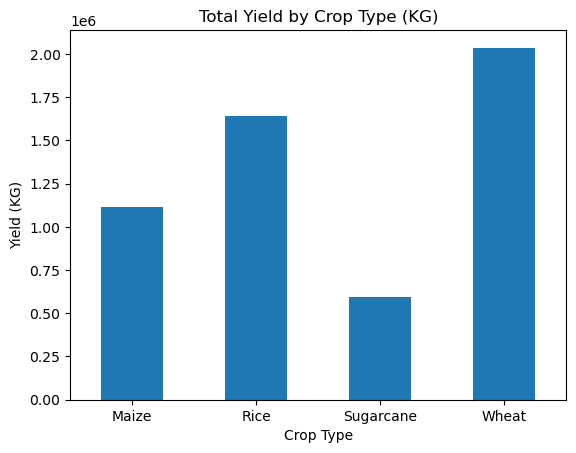

In [17]:
# Step 17: Create a bar chart showing total yield by crop type
total_yield.plot(kind='bar', legend=False)

# Add a title to the chart
plt.title('Total Yield by Crop Type (KG)')

# Add labels to the x-axis and y-axis
plt.xlabel('Crop Type')
plt.ylabel('Yield (KG)')

# Keep crop names horizontal
plt.xticks(rotation=0)

# Display the bar chart
plt.show()

In [18]:
# Step 18: Create a pivot table showing total yield by harvest date
yield_pivot = crop_df.pivot_table(values='YIELD_KG',
                                 index='HARVEST_DATE',
                                 aggfunc='sum')

# Display the pivot table
yield_pivot

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
...,...
2031-03-15,1500.0
2031-03-16,2000.0
2031-03-17,2000.0


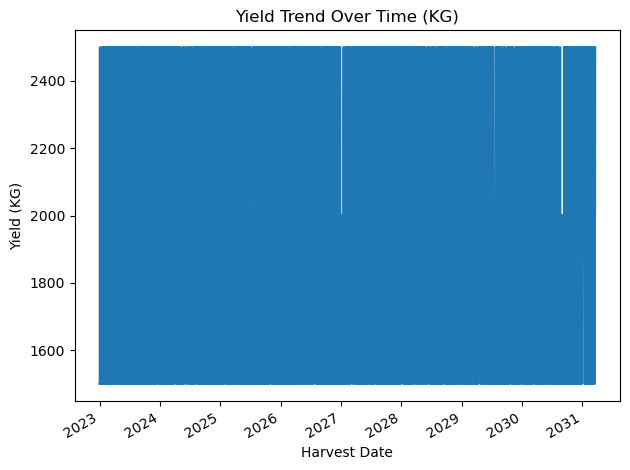

In [19]:
# Step 19: Create a line chart showing the yield trend over time
yield_pivot.plot(kind='line', legend=False)

# Add a title to the chart
plt.title('Yield Trend Over Time (KG)')

# Add labels to the x-axis and y-axis
plt.xlabel('Harvest Date')
plt.ylabel('Yield (KG)')

# Adjust the layout of the chart
plt.tight_layout()

# Save the chart as a PNG image
plt.savefig('crop_yield_trend.png')

# Display the line chart
plt.show()